# M00-4 | Graph Editing: The torch.fx Graph Operations Used Later

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m00_export_basics/04_fx_graph_editing.ipynb)

The first three notebooks only "read" the graph. PT2E's prepare and convert are, at their core, both "graph editing":

- `prepare_pt2e` inserts observers into the graph (you will do this yourself in M02-2).
- `convert_pt2e` replaces observers with quantize/dequantize and precomputes the int8 weights (you will do this yourself in M02-3).

This notebook uses a small conv → relu graph to break the editing actions those two chapters need into six steps:

| Step | Action | API used | Where it is used later |
|---|---|---|---|
| 1 | Insert a new node | `add_submodule`, `inserting_after`, `call_module` | M02-2 |
| 2 | Rewire downstream | `replace_all_uses_with(delete_user_cb=...)` | M02-2 |
| 3 | Regenerate forward | `recompile` | M02-2, M02-3 |
| 4 | Replace with call_function | `inserting_before`, `call_function`, `erase_node` | M02-3 |
| 5 | Put a constant into the graph | `register_buffer`, `get_attr` | M02-3 |
| 6 | Clean up and check | `eliminate_dead_code`, `lint` | M02-3 |

If you are not familiar with the Graph/Node concepts (op kinds, args, users, ...), we suggest first reading "[Some Basic Concepts of PyTorch FX Graph and Node](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/)" (in Chinese),
together with the official [torch.fx documentation](https://docs.pytorch.org/docs/stable/fx.html).

> **Run the cells in order.** All six steps modify **the same `gm` in place**; if you skip around or re-run a cell, the graph will no longer match the explanations. To start over, Restart and run everything from the top.

In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m00_export_basics")

In [2]:
import copy

import torch

from common.models import example_inputs, get_model
from common.pt2e import export_module, quiet
from common.viz import draw

quiet()
_ = torch.manual_seed(0)


def first_line(e):
    """Take only the first line of the exception message (the rest is mostly suggestions and stack info)."""
    return str(e).splitlines()[0]


class Scale(torch.nn.Module):
    """A small demo module: multiplies the input by k. It is only there to give call_module a target whose effect is visible."""

    def __init__(self, k):
        super().__init__()
        self.k = k

    def forward(self, x):
        return x * self.k

## Starting Point: conv → relu

Under `export_module()` is `torch.export.export(...).module()`. `base` saves the original output, and every later step is checked against it.

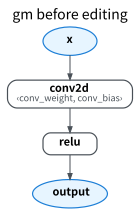

In [3]:
x = example_inputs(4)[0]
gm = export_module(get_model("conv_relu").eval(), (x,))
with torch.no_grad():
    base = gm(x).clone()
graph = gm.graph
nodes = {n.name: n for n in graph.nodes}  # look up nodes by name: x, conv2d, relu, output...
relu = nodes["relu"]
draw(gm, title="gm before editing")

In [4]:
print(f"relu.args  = {relu.args}   <- what it takes (upstream)")
print(f"relu.users = {list(relu.users)}   <- who takes it (downstream)")

relu.args  = (conv2d,)   <- what it takes (upstream)
relu.users = [output]   <- who takes it (downstream)


Graph editing is almost always about these two things: "after which node to insert the new node" and "who should switch to taking the new node".

## Step 1: Insert a New Node

The target of a `call_module` must first be attached to the GraphModule (`add_submodule`). A node created inside the `inserting_after(relu)` context is placed after relu.

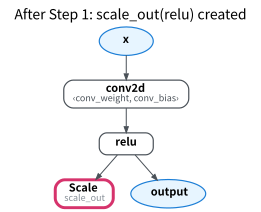

In [5]:
gm.add_submodule("scale_out", Scale(2.0))
with graph.inserting_after(relu):
    scale = graph.call_module("scale_out", (relu,))  # scale_out(relu)
draw(gm, highlight=["scale_out"], title="After Step 1: scale_out(relu) created")

In [6]:
print(f"scale.users = {list(scale.users)}")
assert not scale.users

scale.users = []


`scale_out` takes relu, but **nobody takes it**: output still takes relu. Creating a node does not automatically wire it into the graph; wiring up downstream is the next step.

## Step 2: Rewire Downstream

The goal is to make whoever used to take relu (output) take `scale_out` instead. The intuitive way to write it is `relu.replace_all_uses_with(scale)`.
Let's try it first on a copy, `gm_bad`:

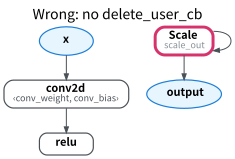

In [7]:
gm_bad = copy.deepcopy(gm)
relu_bad = next(n for n in gm_bad.graph.nodes if n.name == "relu")
scale_bad = next(n for n in gm_bad.graph.nodes if n.name == "scale_out")
relu_bad.replace_all_uses_with(scale_bad)
draw(gm_bad, highlight=["scale_out"], title="Wrong: no delete_user_cb")

In [8]:
print(f"gm_bad scale_out.args = {scale_bad.args}")
try:
    gm_bad.graph.lint()
    lint_error = None
except RuntimeError as e:
    lint_error = first_line(e)
print(f"gm_bad.graph.lint(): {lint_error}")
assert scale_bad.args == (scale_bad,) and lint_error is not None

gm_bad scale_out.args = (scale_out,)
gm_bad.graph.lint(): Argument 'scale_out' of Node 'scale_out' was used before it has been defined! Please check that Nodes in the graph are topologically ordered


`scale_out` has been changed to **take itself** (a self-loop on the graph), and relu is left with no one taking it.
When it was created in Step 1, `scale_out.args = (relu,)`, so `scale_out` itself is also a user of relu; `replace_all_uses_with` rewrites "all" users, including this one.

The correct approach is to exclude the new node itself with `delete_user_cb`:

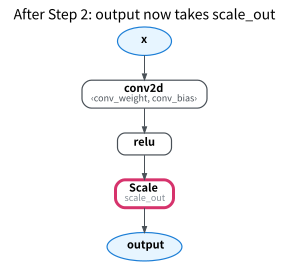

In [9]:
relu.replace_all_uses_with(scale, delete_user_cb=lambda user: user is not scale)
draw(gm, highlight=["scale_out"], title="After Step 2: output now takes scale_out")

In [10]:
print(f"relu.users = {list(relu.users)}   scale.args = {scale.args}")
assert list(relu.users) == [scale] and scale.args == (relu,)

relu.users = [scale_out]   scale.args = (relu,)


The standard way to "insert a new node B after A": B takes A, and everyone else who used to take A now takes B (except B itself).
This is exactly what `prepare_pt2e` does to insert an observer.

## Step 3: recompile

The graph has been edited, but what about the result of calling `gm(x)`?

In [11]:
with torch.no_grad():
    before_recompile = torch.equal(gm(x), base)
gm.recompile()
with torch.no_grad():
    after_recompile = torch.allclose(gm(x), base * 2)
print(f"Graph edited, not yet recompiled: output still equals the original? {before_recompile}")
print(f"After recompile: output == 2 x original output?          {after_recompile}")
assert before_recompile and after_recompile

Graph edited, not yet recompiled: output still equals the original? True
After recompile: output == 2 x original output?          True


The forward of a GraphModule is **code generated from the graph**. Editing the graph does not regenerate it automatically; you must call `recompile()` after every edit.

## Step 4: Replace call_module with call_function

Replace the call_module `scale_out` with an `aten.mul` call_function. `convert_pt2e` replacing an observer (call_module) with q/dq (call_function) follows the same pattern.
The order is: create the new node → switch downstream to the new one → delete the old one. First, see what happens if the order is wrong:

In [12]:
with graph.inserting_before(scale):
    mul = graph.call_function(torch.ops.aten.mul.Tensor, (relu, 2.0))
try:
    graph.erase_node(scale)  # someone still takes scale, so it cannot be deleted
    erase_error = None
except RuntimeError as e:
    erase_error = first_line(e)
print(f"erase_node(scale) directly: {erase_error}")
assert erase_error is not None

erase_node(scale) directly: Tried to erase Node scale_out but it still had 1 users in the graph: {output: None}!


While someone still takes `scale_out`, it cannot be deleted. Do it in the correct order:

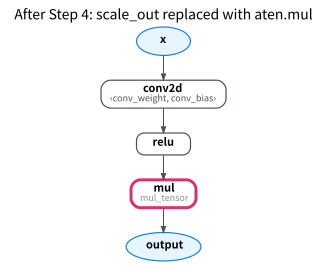

In [13]:
scale.replace_all_uses_with(mul)  # first switch downstream to the new node
graph.erase_node(scale)           # only when nobody takes it can it be deleted
gm.delete_submodule("scale_out")  # drop the module too
gm.recompile()
with torch.no_grad():
    assert torch.allclose(gm(x), base * 2)
draw(gm, highlight=[mul.name], title="After Step 4: scale_out replaced with aten.mul")

The output is still 2x. The second argument of `mul`, `2.0`, is a Python constant written directly into the node's arguments (you cannot see it on the graph; it is not a node).

## Step 5: Put a Tensor Constant into the Graph

A Python number can be written directly into the arguments, and it corresponds to a per-tensor scale/zero point (M01 showed that the scale on q/dq is exactly this).
A tensor constant (corresponding to a per-channel scale/zero point) must first be registered as a buffer and then read out with a `get_attr` node:

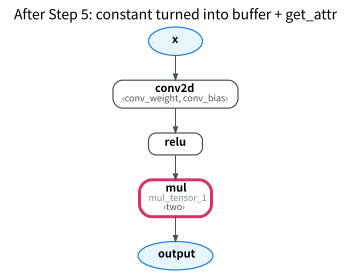

In [14]:
gm.register_buffer("two", torch.tensor(2.0))
with graph.inserting_before(mul):
    two = graph.get_attr("two")  # read the attribute named two on the GraphModule
    mul_t = graph.call_function(torch.ops.aten.mul.Tensor, (relu, two))
mul.replace_all_uses_with(mul_t)
graph.erase_node(mul)
gm.recompile()
with torch.no_grad():
    assert torch.allclose(gm(x), base * 2)
draw(gm, highlight=[mul_t.name], title="After Step 5: constant turned into buffer + get_attr")

`two` is a get_attr, drawn inside the `‹…›` of the label of the `mul` that uses it.

## Step 6: Clean Up and Check

We deliberately create a `neg` that nobody uses, and then clear it out with `eliminate_dead_code`. `lint` checks that the graph structure is consistent (for example, that nodes are defined before they are used) and raises an exception if there is a problem.

In [15]:
with graph.inserting_after(relu):
    graph.call_function(torch.ops.aten.neg.default, (relu,))  # nobody takes it
n_before = len(graph.nodes)
graph.eliminate_dead_code()  # delete every node that has no users and no side effects
n_after = len(graph.nodes)
graph.lint()
gm.recompile()
print(f"node count: after inserting neg {n_before} -> after eliminate_dead_code {n_after}")
assert n_after == n_before - 1 and not any(n.name.startswith("neg") for n in graph.nodes)

node count: after inserting neg 10 -> after eliminate_dead_code 9


After convert precomputes the quantization of the weight and replaces it with a get_attr, the original weight node has no users left, and it too is cleared out by `eliminate_dead_code` (M02-3).

## Summary

| What to do | Action |
|---|---|
| Insert an observer | `add_submodule` + `inserting_after` + `call_module` + `replace_all_uses_with(delete_user_cb=...)` |
| observer → q/dq | `inserting_before` + `call_function` + `replace_all_uses_with` + `erase_node` (+ `delete_submodule`) |
| Store scale/zero point | a Python constant in the arguments, or `register_buffer` + `get_attr` |
| Wrap up | `eliminate_dead_code`, `lint`, `recompile` |

Inserting the observer in M02-2 is Steps 1-3; replacing observers with q/dq and pre-quantizing the weight in M02-3 is Steps 4-6.